<a href="https://colab.research.google.com/github/datapulse-lab-ds/Movie-Budget-Data-Science-project/blob/main/Seaborn_and_Linear_Regression_(start).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introduction

Do higher film budgets lead to more box office revenue? Let's find out if there's a relationship using the movie budgets and financial performance data that I've scraped from [the-numbers.com](https://www.the-numbers.com/movie/budgets) on **May 1st, 2018**.

<img src=https://i.imgur.com/kq7hrEh.png>

In [79]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

In [80]:
pd.options.display.float_format='{:.2f}'.format

from pandas.plotting import register_matplotlib_converters
register_matplotlib_converters()

In [81]:
data = pd.read_csv('cost_revenue_dirty.csv')

In [82]:
print(data.shape)
print(f'Any NAN value among the data: {data.isna().values.any()}')
duplicated_row=data[data.duplicated()]
print(len(duplicated_row))
print(f'Any duplicated? {duplicated_row.values.any()}')
print(data.info())
data.head()

(5391, 6)
Any NAN value among the data: False
0
Any duplicated? False
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5391 entries, 0 to 5390
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Rank                   5391 non-null   int64 
 1   Release_Date           5391 non-null   object
 2   Movie_Title            5391 non-null   object
 3   USD_Production_Budget  5391 non-null   object
 4   USD_Worldwide_Gross    5391 non-null   object
 5   USD_Domestic_Gross     5391 non-null   object
dtypes: int64(1), object(5)
memory usage: 252.8+ KB
None


,Rank,Release_Date,Movie_Title,USD_Production_Budget,USD_Worldwide_Gross,USD_Domestic_Gross
0,5293,8/2/1915,The Birth of a Nation,"$110,000","$11,000,000","$10,000,000"
1,5140,5/9/1916,Intolerance,"$385,907",$0,$0
2,5230,12/24/1916,"20,000 Leagues Under the Sea","$200,000","$8,000,000","$8,000,000"
3,5299,9/17/1920,Over the Hill to the Poorhouse,"$100,000","$3,000,000","$3,000,000"
4,5222,1/1/1925,The Big Parade,"$245,000","$22,000,000","$11,000,000"


In [83]:
chars_to_remove=[',','$']
columns_to_clean=['USD_Production_Budget','USD_Worldwide_Gross','USD_Domestic_Gross']

for col in columns_to_clean:
  for char in chars_to_remove:
    data[col]=data[col].astype(str).str.replace(char,"")
  data[col]=pd.to_numeric(data[col])

print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5391 entries, 0 to 5390
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Rank                   5391 non-null   int64 
 1   Release_Date           5391 non-null   object
 2   Movie_Title            5391 non-null   object
 3   USD_Production_Budget  5391 non-null   int64 
 4   USD_Worldwide_Gross    5391 non-null   int64 
 5   USD_Domestic_Gross     5391 non-null   int64 
dtypes: int64(4), object(2)
memory usage: 252.8+ KB
None


In [84]:
data.Release_Date=pd.to_datetime(data.Release_Date)
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5391 entries, 0 to 5390
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Rank                   5391 non-null   int64         
 1   Release_Date           5391 non-null   datetime64[ns]
 2   Movie_Title            5391 non-null   object        
 3   USD_Production_Budget  5391 non-null   int64         
 4   USD_Worldwide_Gross    5391 non-null   int64         
 5   USD_Domestic_Gross     5391 non-null   int64         
dtypes: datetime64[ns](1), int64(4), object(1)
memory usage: 252.8+ KB


In [85]:
data.describe()

,Rank,Release_Date,USD_Production_Budget,USD_Worldwide_Gross,USD_Domestic_Gross
count,5391.00,5391,5391.00,5391.00,5391.00
mean,2696.00,2003-09-19 15:02:02.203672704,31113737.58,88855421.96,41235519.44
min,1.00,1915-08-02 00:00:00,1100.00,0.00,0.00
25%,1348.50,1999-12-02 12:00:00,5000000.00,3865206.00,1330901.50
50%,2696.00,2006-06-23 00:00:00,17000000.00,27450453.00,17192205.00
75%,4043.50,2011-11-23 00:00:00,40000000.00,96454455.00,52343687.00
max,5391.00,2020-12-31 00:00:00,425000000.00,2783918982.00,936662225.00
std,1556.39,NaN,40523796.88,168457757.00,66029346.27


In [86]:
zero_domestic=data[data.USD_Worldwide_Gross==0]
print(f"Number of films that grossed $0 domestically {zero_domestic}")
zero_domestic.sort_values('USD_Production_Budget',ascending=False)

Number of films that grossed $0 domestically       Rank Release_Date                       Movie_Title  \
1     5140   1916-05-09                       Intolerance   
6     4630   1927-12-08                             Wings   
8     4240   1930-01-01                     Hell's Angels   
17    4814   1936-10-20  Charge of the Light Brigade, The   
27    4789   1941-10-28           How Green Was My Valley   
...    ...          ...                               ...   
5386  2950   2018-10-08                               Meg   
5387   126   2018-12-18                           Aquaman   
5388    96   2020-12-31                       Singularity   
5389  1119   2020-12-31            Hannibal the Conqueror   
5390  2517   2020-12-31    Story of Bonnie and Clyde, The   

      USD_Production_Budget  USD_Worldwide_Gross  USD_Domestic_Gross  
1                    385907                    0                   0  
6                   2000000                    0                   0  
8        

,Rank,Release_Date,Movie_Title,USD_Production_Budget,USD_Worldwide_Gross,USD_Domestic_Gross
5388,96,2020-12-31,Singularity,175000000,0,0
5387,126,2018-12-18,Aquaman,160000000,0,0
5384,321,2018-09-03,A Wrinkle in Time,103000000,0,0
5385,366,2018-10-08,Amusement Park,100000000,0,0
5058,880,2015-11-12,The Ridiculous 6,60000000,0,0
...,...,...,...,...,...,...
4787,5371,2014-12-31,Stories of Our Lives,15000,0,0
3056,5374,2007-12-31,Tin Can Man,12000,0,0
4907,5381,2015-05-19,Family Motocross,10000,0,0
5006,5389,2015-09-29,Signed Sealed Delivered,5000,0,0


In [87]:
zero_worldwide=data[data.USD_Worldwide_Gross	== 0]
print(f"Number of films that grossed $0 worldwide {zero_worldwide}")
zero_worldwide.sort_values('USD_Production_Budget',ascending=False)

Number of films that grossed $0 worldwide       Rank Release_Date                       Movie_Title  \
1     5140   1916-05-09                       Intolerance   
6     4630   1927-12-08                             Wings   
8     4240   1930-01-01                     Hell's Angels   
17    4814   1936-10-20  Charge of the Light Brigade, The   
27    4789   1941-10-28           How Green Was My Valley   
...    ...          ...                               ...   
5386  2950   2018-10-08                               Meg   
5387   126   2018-12-18                           Aquaman   
5388    96   2020-12-31                       Singularity   
5389  1119   2020-12-31            Hannibal the Conqueror   
5390  2517   2020-12-31    Story of Bonnie and Clyde, The   

      USD_Production_Budget  USD_Worldwide_Gross  USD_Domestic_Gross  
1                    385907                    0                   0  
6                   2000000                    0                   0  
8           

,Rank,Release_Date,Movie_Title,USD_Production_Budget,USD_Worldwide_Gross,USD_Domestic_Gross
5388,96,2020-12-31,Singularity,175000000,0,0
5387,126,2018-12-18,Aquaman,160000000,0,0
5384,321,2018-09-03,A Wrinkle in Time,103000000,0,0
5385,366,2018-10-08,Amusement Park,100000000,0,0
5058,880,2015-11-12,The Ridiculous 6,60000000,0,0
...,...,...,...,...,...,...
4787,5371,2014-12-31,Stories of Our Lives,15000,0,0
3056,5374,2007-12-31,Tin Can Man,12000,0,0
4907,5381,2015-05-19,Family Motocross,10000,0,0
5006,5389,2015-09-29,Signed Sealed Delivered,5000,0,0


In [88]:
international_releases=data.query('USD_Worldwide_Gross!=0 and USD_Domestic_Gross==0')
print(international_releases)

      Rank Release_Date              Movie_Title  USD_Production_Budget  \
71    4310   1956-02-16                 Carousel                3380000   
1579  5087   2001-02-11  Everything Put Together                 500000   
1744  3695   2001-12-31                 The Hole                7500000   
2155  4236   2003-12-31                  Nothing                4000000   
2203  2513   2004-03-31                The Touch               20000000   
...    ...          ...                      ...                    ...   
5340  1506   2017-04-14      Queen of the Desert               36000000   
5348  2225   2017-05-05        Chāi dàn zhuānjiā               23000000   
5360  4832   2017-07-03                Departure                1100000   
5372  1856   2017-08-25                Ballerina               30000000   
5374  4237   2017-08-25     Polina danser sa vie                4000000   

      USD_Worldwide_Gross  USD_Domestic_Gross  
71                   3220                   0  
157

In [89]:
# Date of Data Collection
scrape_date=pd.Timestamp('2018-5-1')

In [90]:
future_relese=data[data.Release_Date >= scrape_date]
print(future_relese)
data_clean=data.drop(future_relese.index)

      Rank Release_Date                     Movie_Title  \
5384   321   2018-09-03               A Wrinkle in Time   
5385   366   2018-10-08                  Amusement Park   
5386  2950   2018-10-08                             Meg   
5387   126   2018-12-18                         Aquaman   
5388    96   2020-12-31                     Singularity   
5389  1119   2020-12-31          Hannibal the Conqueror   
5390  2517   2020-12-31  Story of Bonnie and Clyde, The   

      USD_Production_Budget  USD_Worldwide_Gross  USD_Domestic_Gross  
5384              103000000                    0                   0  
5385              100000000                    0                   0  
5386               15000000                    0                   0  
5387              160000000                    0                   0  
5388              175000000                    0                   0  
5389               50000000                    0                   0  
5390               20000000   

In [91]:
losing_money=data_clean[data_clean.USD_Production_Budget > data_clean.USD_Worldwide_Gross]
print((len(losing_money)/len(data_clean)) *100)

37.27711738484398


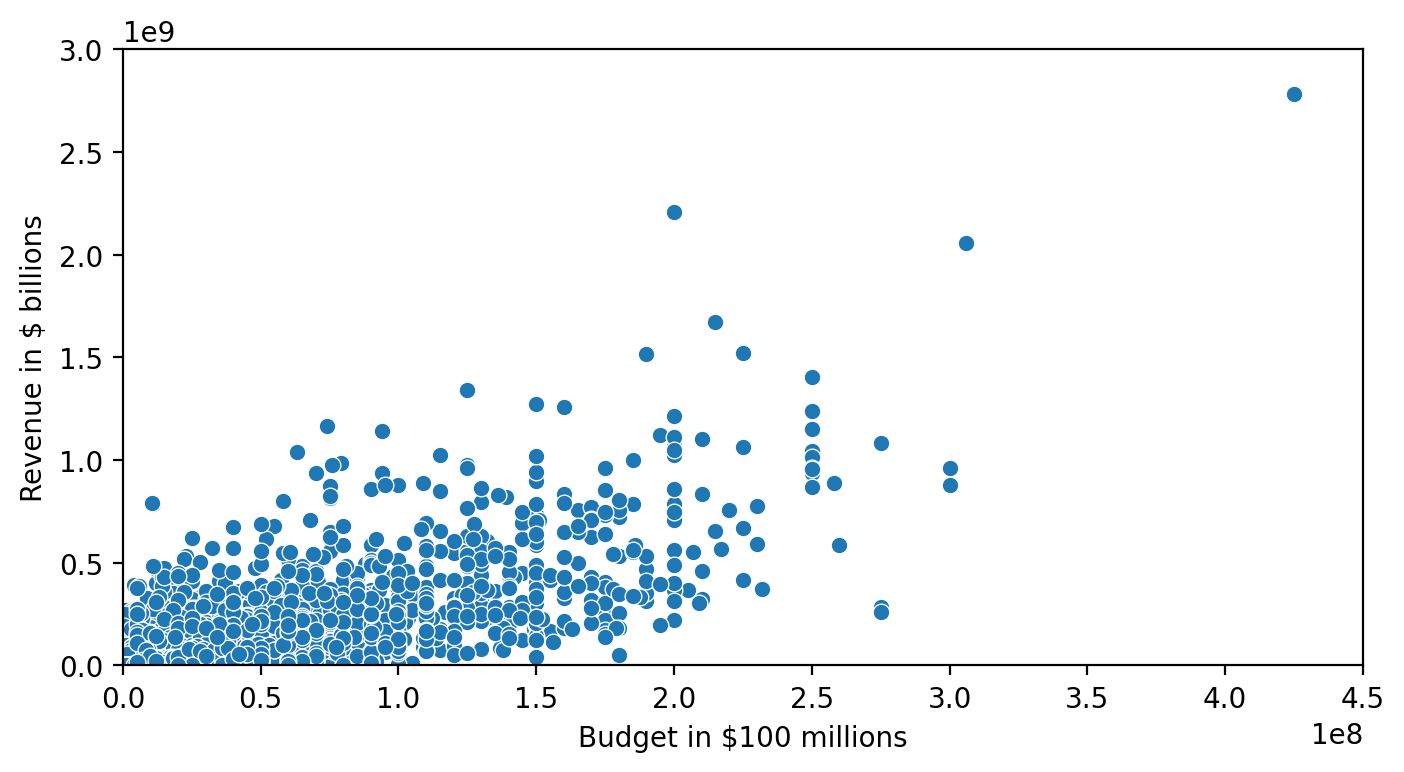

In [92]:
plt.figure(figsize=(8,4),dpi=200)
ax=sns.scatterplot(data=data_clean,x='USD_Production_Budget',y='USD_Worldwide_Gross')
ax.set(ylim=(0,3000000000),
       xlim=(0,450000000),
       ylabel='Revenue in $ billions',
       xlabel='Budget in $100 millions')
plt.show()

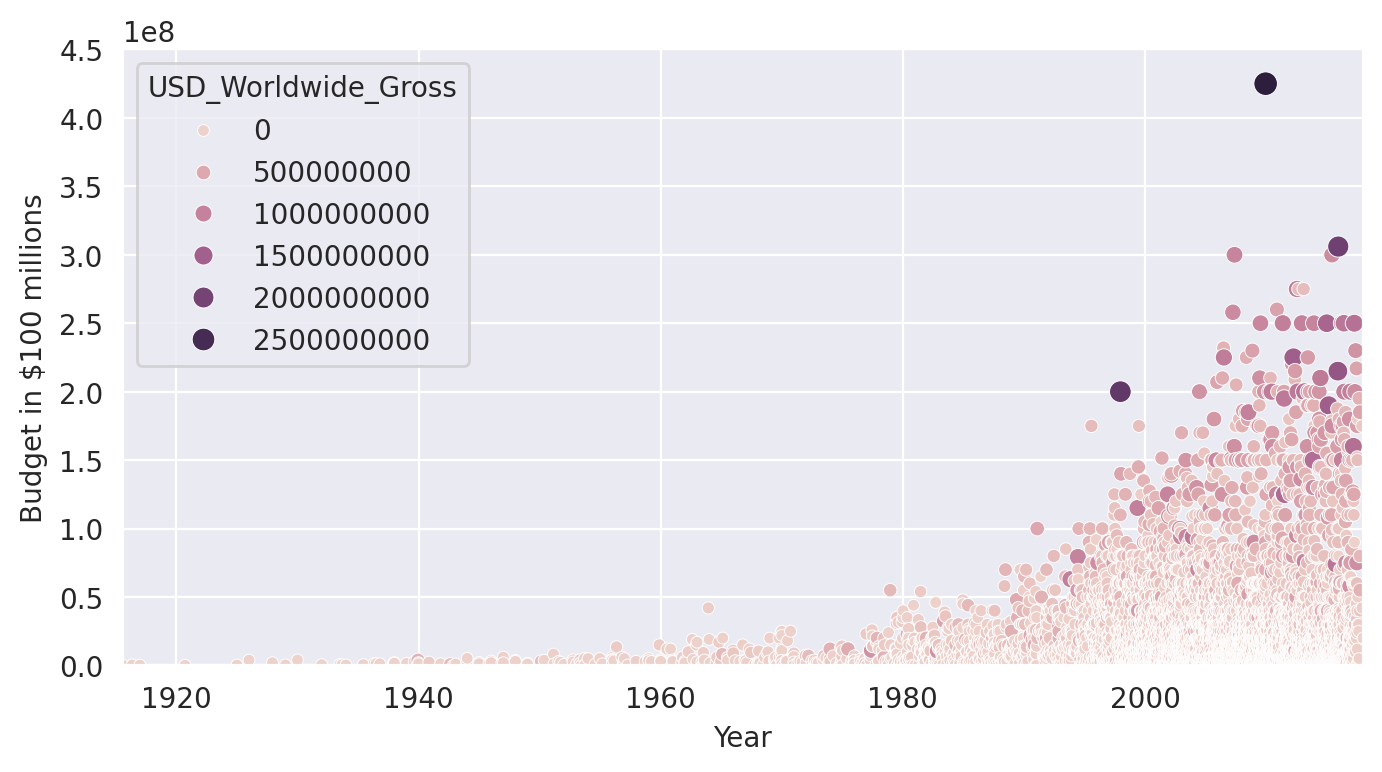

In [93]:
plt.figure(figsize=(8,4),dpi=200)

with sns.axes_style('darkgrid'):
  ax=sns.scatterplot(data=data_clean,x='Release_Date',
                     y='USD_Production_Budget',
                     hue='USD_Worldwide_Gross',
                     size='USD_Worldwide_Gross')

  ax.set(ylim=(0,450000000),
         xlim=(data_clean.Release_Date.min(),
               data_clean.Release_Date.max()),
         ylabel='Budget in $100 millions',
         xlabel='Year')

In [94]:
dt_index=pd.DatetimeIndex(data_clean.Release_Date)
years=dt_index.year
decades=years//10*10
data_clean['Decades']=decades

In [95]:
old_flims=data_clean[data_clean.Decades<=1960]
new_flims=data_clean[data_clean.Decades>1960]
old_flims.describe()
old_flims.sort_values('USD_Production_Budget',ascending=False).head()

,Rank,Release_Date,Movie_Title,USD_Production_Budget,USD_Worldwide_Gross,USD_Domestic_Gross,Decades
109,1253,1963-12-06,Cleopatra,42000000,71000000,57000000,1960
150,2175,1969-12-16,"Hello, Dolly",24000000,33208099,33208099,1960
118,2425,1965-02-15,The Greatest Story Ever Told,20000000,15473333,15473333,1960
143,2465,1969-01-01,Sweet Charity,20000000,8000000,8000000,1960
148,2375,1969-10-15,Paint Your Wagon,20000000,31678778,31678778,1960


# Seaborn Regression Plots

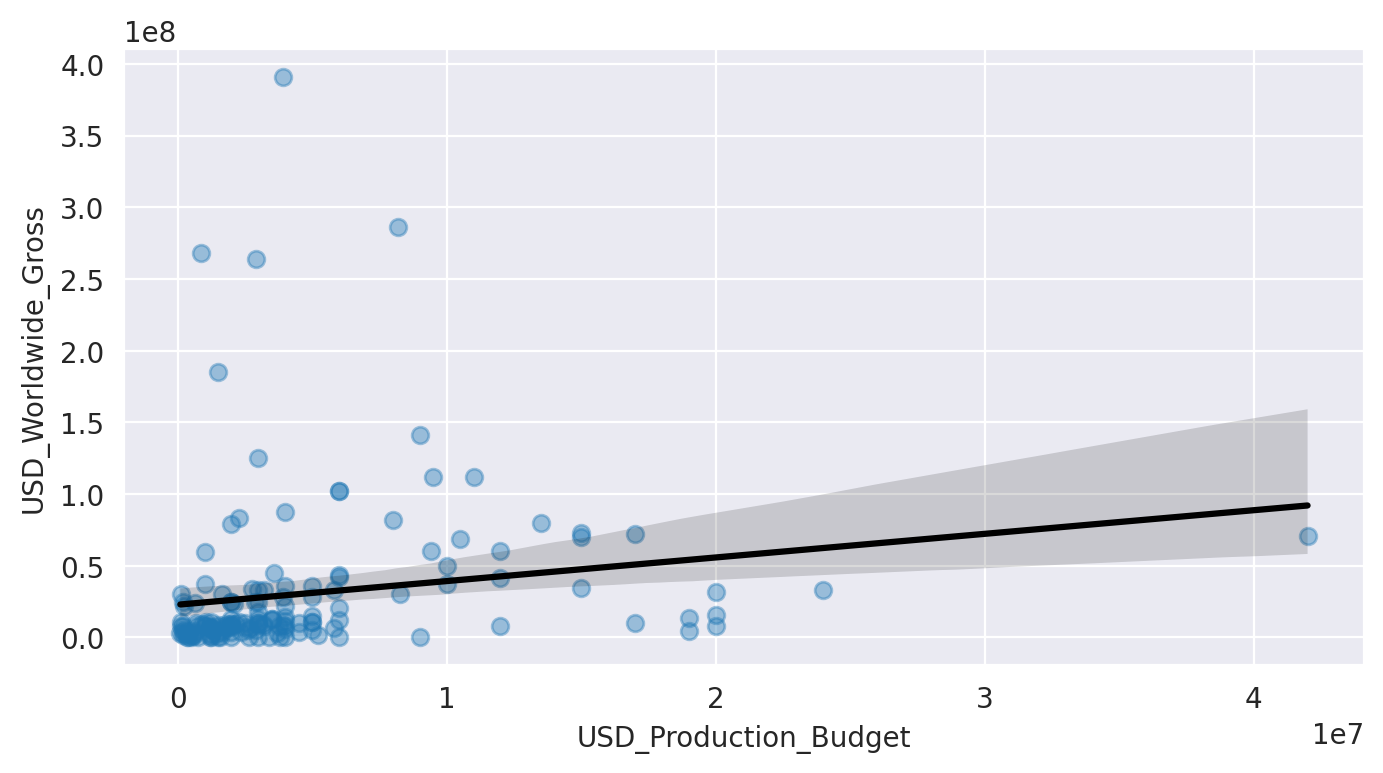

In [96]:
plt.figure(figsize=(8,4),dpi=200)

with sns.axes_style('darkgrid'):
  ax=sns.regplot(data=old_flims,
                 x='USD_Production_Budget',
                 y='USD_Worldwide_Gross',
                 scatter_kws={'alpha':0.4},
                 line_kws={'color':'black'}
)


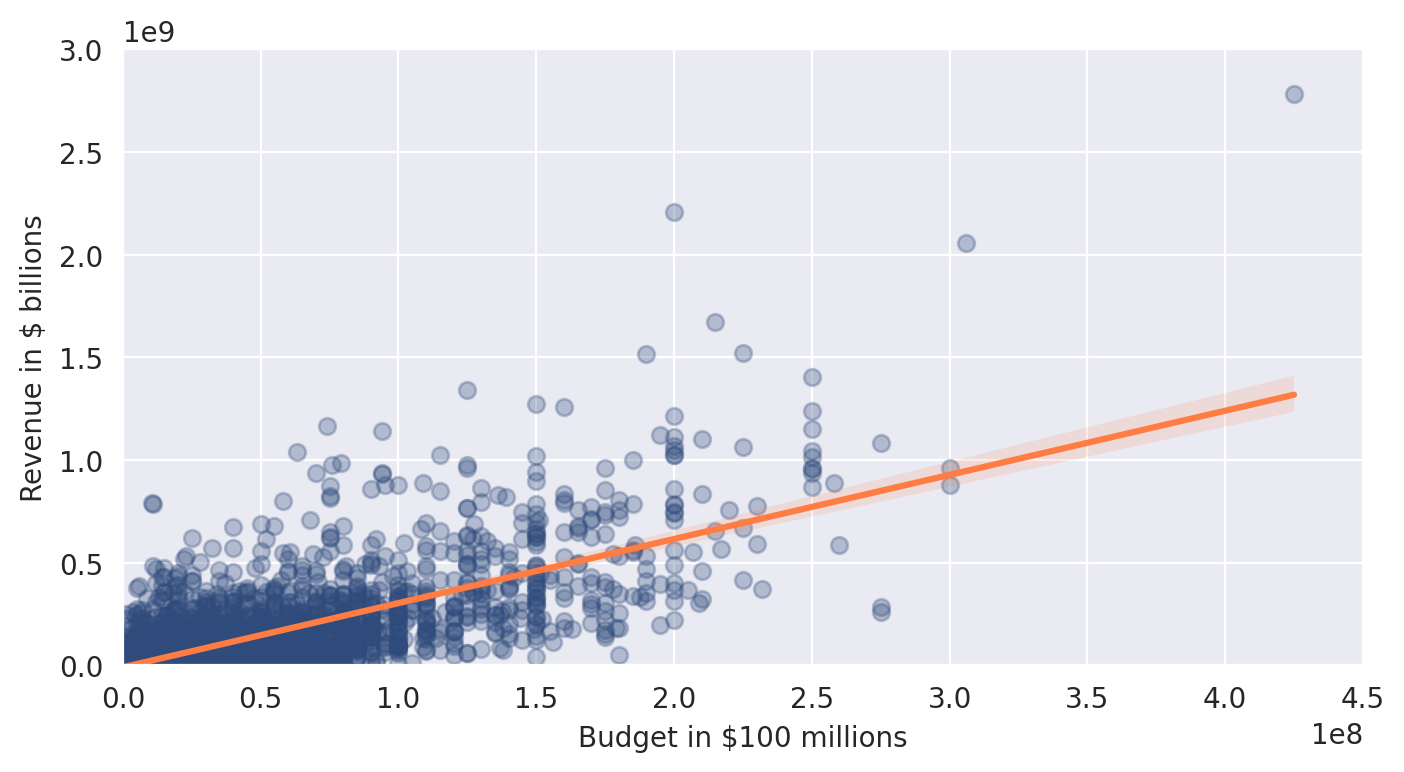

In [97]:
plt.figure(figsize=(8,4),dpi=200)

with sns.axes_style('darkgrid'):
  ax=sns.regplot(data=new_flims,
                 x='USD_Production_Budget',
                 y='USD_Worldwide_Gross',
                 color='#2f4b7c',
                 scatter_kws={'alpha':0.3},
                 line_kws={'color': '#ff7c43'})
  ax.set(ylim=(0,3000000000),
         xlim=(0,450000000),
         ylabel='Revenue in $ billions',
         xlabel='Budget in $100 millions')

# Run My Own Regression with scikit-learn

$$ REV \hat ENUE = \theta _0 + \theta _1 BUDGET$$

In [98]:
regression=LinearRegression()
X=pd.DataFrame(new_flims,columns=['USD_Production_Budget'])
y=pd.DataFrame(new_flims,columns=['USD_Worldwide_Gross'])
model=regression.fit(X,y)
print(regression.intercept_)
print(regression.coef_)

[-8650768.00661027]
[[3.12259592]]


Run a linear regression for the `old_films`. Calculate the intercept, slope and r-squared. How much of the variance in movie revenue does the linear model explain in this case?

In [99]:
X=pd.DataFrame(old_flims,columns=['USD_Production_Budget'])
y=pd.DataFrame(old_flims,columns=['USD_Worldwide_Gross'])
model=regression.fit(X,y)
print(regression.intercept_)
print(regression.coef_)

[22821538.63508039]
[[1.64771314]]


how much global revenue does our model estimate for a film with a budget of $350 million?

In [100]:
budget=350000000
revenue_estimate=regression.intercept_[0]+regression.coef_[0,0]*budget
print(f'The estimated revenue for a $350 film is around ${revenue_estimate}.')
revenue_estimate = round(revenue_estimate, -6)
print(revenue_estimate)

The estimated revenue for a $350 film is around $599521139.0388364.
600000000.0
